In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

from sklearn import metrics
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV

RANDOM_STATE = 42

## 1. Data Acquisition

In [2]:
raw = yf.download("^GSPC", start="2021-01-01", end="2025-12-31", auto_adjust=True, progress=False)
raw.columns = raw.columns.get_level_values(0)
raw.index.name = "Date"
raw.to_csv("sp500_data.csv")
print(raw.shape)
raw.tail()

(1254, 5)


Price,Close,High,Low,Open,Volume
Date,,,,,
2025-12-23,6909.790039,6910.879883,6868.810059,6872.410156,3820560000
2025-12-24,6932.049805,6937.319824,6904.910156,6904.910156,1798270000
2025-12-26,6929.939941,6945.770020,6921.600098,6936.020020,2586550000
2025-12-29,6905.740234,6920.209961,6888.759766,6903.600098,3541750000
2025-12-30,6896.240234,6913.250000,6893.470215,6900.439941,3309930000


## 2. Feature Engineering

All features are calculated using data up to day *t*. The target variable is the return of day *t+1*.

In [3]:
df = raw[["Open", "High", "Low", "Close", "Volume"]].copy()

df["ret"] = df["Close"].pct_change()
for k in (0, 1, 2, 4):
    df[f"ret_lag{k}"] = df["ret"].shift(k)

df["hl_range"] = (df["High"] - df["Low") / df["Close"]
df["oc_change"] = (df["Close"] - df["Open"]) / df["Open"]

df["ma5_ratio"] = df["Close"] / df["Close"].rolling(5).mean() - 1
df["ma20_ratio"] = df["Close"] / df["Close"].rolling(20).mean() - 1
df["vol5"] = df["ret"].rolling(5).std()
df["vol20"] = df["ret"].rolling(20).std()

df["vol_chg"] = df["Volume"].pct_change().replace([np.inf, -np.inf], np.nan)

df["target"] = df["ret"].shift(-1)

features = ["ret_lag0", "ret_lag1", "ret_lag2", "ret_lag4", "hl_range", "oc_change",
            "ma5_ratio", "ma20_ratio", "vol5", "vol20", "vol_chg"]
X_latest = df[features].iloc[[-1]]
df = df.dropna()
X, y = df[features], df["target"]
print(X.shape, "| features:", len(features))

(1232, 11) | fitur: 11


## 3. Chronological Split (No Shuffling)

In [4]:
split = int(len(df) * 0.74)
X_train, X_test = X.iloc[:split], X.iloc[split:]
y_train, y_test = y.iloc[:split], y.iloc[split:]
print("Train:", X_train.index.min().date(), "->", X_train.index.max().date())
print("Test :", X_test.index.min().date(), "->", X_test.index.max().date())

Train: 2021-02-02 -> 2024-09-17
Test : 2024-09-18 -> 2025-12-29


## 4. Model Definition and Tuning

Tuning is performed using `TimeSeriesSplit` to ensure validation folds always succeed the training folds chronologically.

In [16]:
tscv = TimeSeriesSplit(n_splits=5)

models = {
    "Baseline (train mean)": DummyRegressor(strategy="mean"),
    "Linear Regression": LinearRegression(),
    "Ridge": GridSearchCV(
        make_pipeline(StandardScaler(), Ridge()),
        {"ridge__alpha": [0.1, 1, 10, 100, 1000]},
        cv=tscv, scoring="neg_mean_absolute_error"),
    "Decision Tree": GridSearchCV(
        DecisionTreeRegressor(random_state=RANDOM_STATE),
        {"max_depth": [2, 3, 4, 5], "min_samples_leaf": [10, 20, 40]},
        cv=tscv, scoring="neg_mean_absolute_error"),
    "Random Forest": GridSearchCV(
        RandomForestRegressor(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1),
        {"max_depth": [2, 3, 5], "min_samples_leaf": [10, 20, 40]},
        cv=tscv, scoring="neg_mean_absolute_error"),
    "Gradient Boosting": GridSearchCV(
        GradientBoostingRegressor(random_state=RANDOM_STATE),
        {"n_estimators": [50, 100], "max_depth": [2, 3], "learning_rate": [0.03, 0.1], "subsample": [0.7]},
        cv=tscv, scoring="neg_mean_absolute_error"),
}

preds = {}
for name, m in models.items():
    m.fit(X_train, y_train)
    preds[name] = m.predict(X_test)
    if hasattr(m, "best_params_"):
        print(f"{name:20s} best params: {m.best_params_}")

Ridge                best params: {'ridge__alpha': 1000}
Decision Tree        best params: {'max_depth': 2, 'min_samples_leaf': 40}
Random Forest        best params: {'max_depth': 2, 'min_samples_leaf': 40}
Gradient Boosting    best params: {'learning_rate': 0.03, 'max_depth': 2, 'n_estimators': 50, 'subsample': 0.7}


## 5. Evaluation

We evaluate performance on **returns** (MAE, RMSE, $R^2$, and directional accuracy) and compute MAE on **prices** (by converting predicted returns back to next-day closing prices). The "persistence" baseline assumes tomorrow's price is identical to today's price.

In [17]:
close_today = df["Close"].iloc[split:]
actual_price = close_today * (1 + y_test)

rows = []
for name, p in preds.items():
    price_pred = close_today * (1 + p)
    rows.append({
        "Model": name,
        "MAE return": metrics.mean_absolute_error(y_test, p),
        "RMSE return": np.sqrt(metrics.mean_squared_error(y_test, p)),
        "R2 return": metrics.r2_score(y_test, p),
        "Directional accuracy": np.mean(np.sign(p) == np.sign(y_test)),
        "MAE price": metrics.mean_absolute_error(actual_price, price_pred),
    })

rows.append({
    "Model": "Persistence (tomorrow price = today)",
    "MAE return": metrics.mean_absolute_error(y_test, np.zeros(len(y_test))),
    "RMSE return": np.sqrt(metrics.mean_squared_error(y_test, np.zeros(len(y_test)))),
    "R2 return": metrics.r2_score(y_test, np.zeros(len(y_test))),
    "Directional accuracy": np.nan,
    "MAE price": metrics.mean_absolute_error(actual_price, close_today),
})

results = pd.DataFrame(rows).set_index("Model").round(5)
results.sort_values("MAE price")

,MAE return,RMSE return,R2 return,Directional accuracy,MAE price
Model,,,,,
Baseline (train mean),0.00689,0.01102,-0.00046,0.57321,41.17356
Gradient Boosting,0.00692,0.01094,0.01355,0.55452,41.37923
Persistence (tomorrow price = today),0.00694,0.01104,-0.00402,NaN,41.46538
Ridge,0.00694,0.01098,0.00643,0.52336,41.47410
Random Forest,0.00697,0.01107,-0.00991,0.52336,41.68232
Linear Regression,0.00698,0.01089,0.02339,0.52648,41.80587
Decision Tree,0.00712,0.01135,-0.06149,0.56075,42.54650


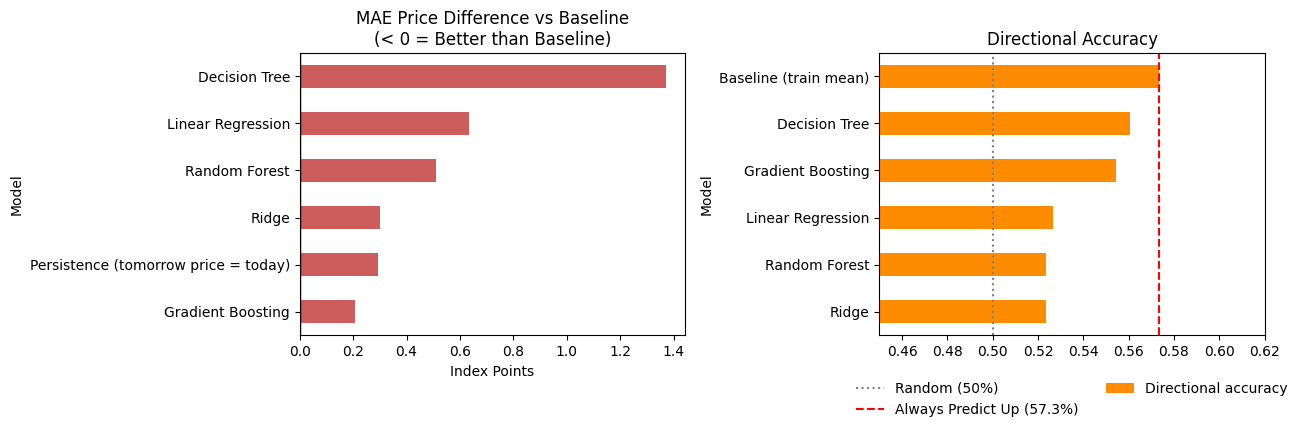

In [18]:
base_mae = results.loc["Baseline (train mean)", "MAE price"]
always_up = np.mean(y_test > 0)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

diff = (results["MAE price"] - base_mae).drop(index="Baseline (train mean)").sort_values()
diff.plot.barh(ax=axes[0], color=["seagreen" if v < 0 else "indianred" for v in diff])
axes[0].axvline(0, color="black", lw=1)
axes[0].set_title("MAE Price Difference vs Baseline\n(< 0 = Better than Baseline)")
axes[0].set_xlabel("Index Points")

acc = results["Directional accuracy"].dropna().sort_values()
acc.plot.barh(ax=axes[1], color="darkorange", legend=False)
axes[1].axvline(0.5, color="gray", ls=":", label="Random (50%)")
axes[1].axvline(always_up, color="red", ls="--", label=f"Always Predict Up ({always_up:.1%})")
axes[1].set_xlim(0.45, 0.62)
axes[1].set_title("Directional Accuracy")
axes[1].legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2, frameon=False)

plt.tight_layout(); plt.show()

## 6. Statistical Significance: Diebold-Mariano Test

In [19]:
from scipy import stats

def diebold_mariano(y_true, p_model, p_ref, loss="se"):
    e_m = np.asarray(y_true) - np.asarray(p_model)
    e_r = np.asarray(y_true) - np.asarray(p_ref)
    d = (e_m**2 - e_r**2) if loss == "se" else (np.abs(e_m) - np.abs(e_r))
    n = len(d)
    dm = d.mean() / np.sqrt(d.var(ddof=1) / n)
    dm *= np.sqrt((n - 1) / n)
    p = 2 * (1 - stats.t.cdf(abs(dm), df=n - 1))
    return dm, p

def dm_table(pred_dict, y_true, ref="Baseline (train mean)"):
    rows = []
    for name, p in pred_dict.items():
        if name == ref:
            continue
        dm_se, p_se = diebold_mariano(y_true, p, pred_dict[ref], "se")
        dm_ae, p_ae = diebold_mariano(y_true, p, pred_dict[ref], "ae")
        sig = [("better" if dm < 0 else "worse") for dm, p in ((dm_se, p_se), (dm_ae, p_ae)) if p < 0.05]
        rows.append({"Model": name, "DM (squared)": dm_se, "p (squared)": p_se,
                     "DM (absolute)": dm_ae, "p (absolute)": p_ae,
                     "Significant vs Baseline?": " / ".join(sorted(set(sig))) if sig else "No"})
    return pd.DataFrame(rows).set_index("Model").round(4)

dm_table(preds, y_test)

,DM (squared),p (squared),DM (absolute),p (absolute),Significant vs Baseline?
Model,,,,,
Linear Regression,-0.7137,0.4759,1.0999,0.2722,No
Ridge,-0.6375,0.5243,1.5936,0.1120,No
Decision Tree,3.6655,0.0003,2.5117,0.0125,worse
Random Forest,0.8790,0.3800,2.1448,0.0327,worse
Gradient Boosting,-0.7374,0.4614,0.5644,0.5729,No


## 7. Actual vs. Predicted (Test Data)

Best model (MAE price): Gradient Boosting


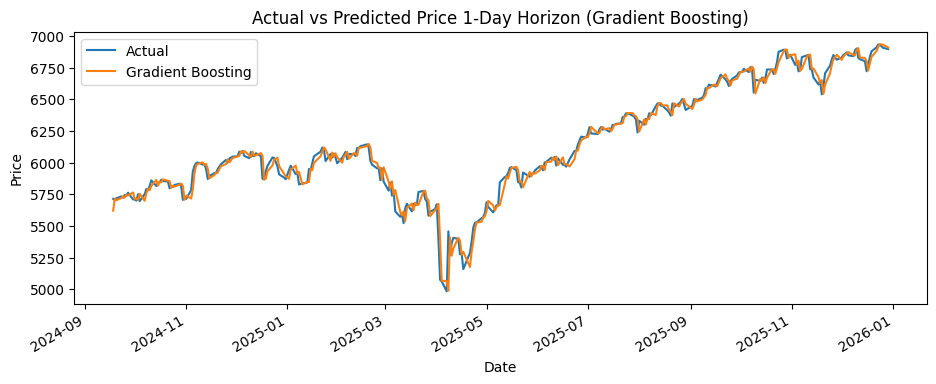

In [20]:
candidates = results.drop(index=["Persistence (tomorrow price = today)", "Baseline (train mean)"])
best_name = candidates["MAE price"].idxmin()
print("Best model (MAE price):", best_name)

plot_df = pd.DataFrame({
    "Actual": actual_price,
    best_name: close_today * (1 + preds[best_name]),
})
plot_df.plot(figsize=(11, 4), title=f"Actual vs Predicted Price 1-Day Horizon ({best_name})")
plt.ylabel("Price"); plt.show()

## 8. Simple Backtest

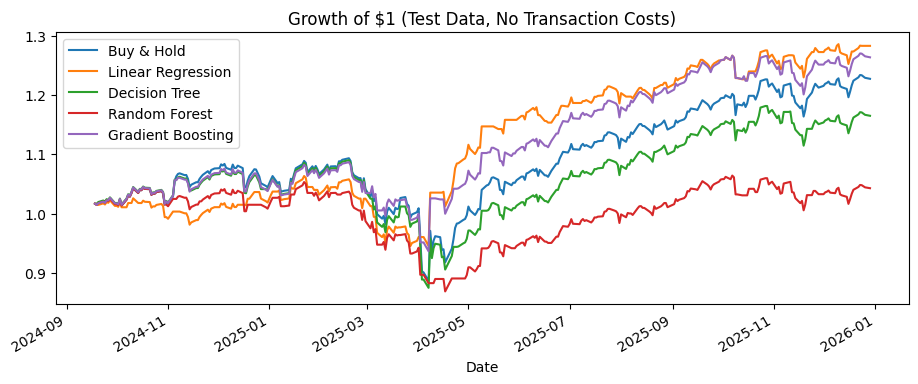

,2025-12-29
Linear Regression,1.283
Gradient Boosting,1.264
Buy & Hold,1.227
Decision Tree,1.165
Random Forest,1.043


In [21]:
bt = pd.DataFrame({"Buy & Hold": (1 + y_test).cumprod()})
for name in ["Linear Regression", "Decision Tree", "Random Forest", "Gradient Boosting"]:
    signal = (preds[name] > 0).astype(int)
    bt[name] = (1 + y_test * signal).cumprod()

bt.plot(figsize=(11, 4), title="Growth of $1 (Test Data, No Transaction Costs)")
plt.show()
bt.iloc[-1].round(3).sort_values(ascending=False)

## 9. Walk-Forward Validation

In [22]:
from sklearn.base import clone

REFIT_EVERY = 21

def walk_forward(estimator, X, y, start, step=REFIT_EVERY):
    out = []
    for i in range(start, len(X), step):
        m = clone(estimator)
        m.fit(X.iloc[:i], y.iloc[:i])
        out.append(pd.Series(m.predict(X.iloc[i:i + step]), index=X.index[i:i + step]))
    return pd.concat(out)

fixed = {n: (m.best_estimator_ if hasattr(m, "best_estimator_") else m) for n, m in models.items()}
wf_preds = {n: walk_forward(est, X, y, split).values for n, est in fixed.items()}

def evaluate(pred_dict, y_true, close_t):
    act_price = close_t * (1 + y_true)
    rows = []
    for n, p in pred_dict.items():
        rows.append({"Model": n,
                     "MAE return": metrics.mean_absolute_error(y_true, p),
                     "RMSE return": np.sqrt(metrics.mean_squared_error(y_true, p)),
                     "R2 return": metrics.r2_score(y_true, p),
                     "Directional accuracy": np.mean(np.sign(p) == np.sign(y_true)),
                     "MAE price": metrics.mean_absolute_error(act_price, close_t * (1 + p))})
    return pd.DataFrame(rows).set_index("Model").round(5).sort_values("MAE price")

wf_results = evaluate(wf_preds, y_test, close_today)
wf_results

,MAE return,RMSE return,R2 return,Directional accuracy,MAE price
Model,,,,,
Baseline (train mean),0.00689,0.01102,-0.00099,0.57321,41.18623
Gradient Boosting,0.00689,0.01104,-0.00395,0.55452,41.20473
Decision Tree,0.00692,0.01084,0.03203,0.57321,41.38568
Ridge,0.00694,0.01098,0.00603,0.51402,41.50351
Random Forest,0.00696,0.01103,-0.00241,0.53583,41.61797
Linear Regression,0.00698,0.01087,0.02646,0.48910,41.80705


### Diebold-Mariano Test on Walk-Forward Predictions:

In [23]:
dm_table(wf_preds, y_test)

,DM (squared),p (squared),DM (absolute),p (absolute),Significant vs Baseline?
Model,,,,,
Linear Regression,-0.8490,0.3965,0.9867,0.3245,No
Ridge,-0.6462,0.5186,1.5380,0.1250,No
Decision Tree,-0.7974,0.4258,0.2722,0.7856,No
Random Forest,0.1186,0.9056,1.8702,0.0624,No
Gradient Boosting,0.1145,0.9089,0.0274,0.9781,No


### Walk-Forward Backtest with Transaction Costs

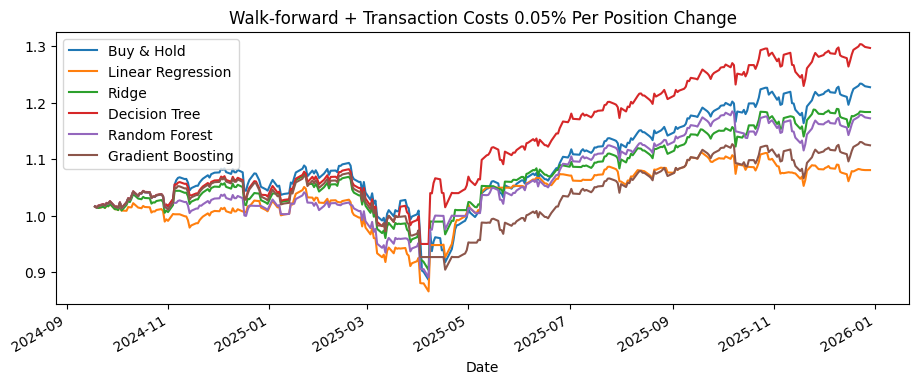

,Final value,Number of trades
Decision Tree,1.297,19.0
Buy & Hold,1.227,NaN
Ridge,1.184,80.0
Random Forest,1.173,49.0
Gradient Boosting,1.125,33.0
Linear Regression,1.081,108.0


In [24]:
COST = 0.0005

def strategy_returns(signal, ret, cost=COST):
    signal = pd.Series(signal, index=ret.index).astype(int)
    trades = signal.diff().abs().fillna(signal.abs())
    return ret * signal - cost * trades, int(trades.sum())

bt_wf = pd.DataFrame({"Buy & Hold": (1 + y_test).cumprod()})
n_trades = {}
for name in ["Linear Regression", "Ridge", "Decision Tree", "Random Forest", "Gradient Boosting"]:
    r, n_t = strategy_returns(wf_preds[name] > 0, y_test)
    bt_wf[name] = (1 + r).cumprod()
    n_trades[name] = n_t

bt_wf.plot(figsize=(11, 4), title=f"Walk-forward + Transaction Costs {COST:.2%} Per Position Change")
plt.show()

summary = pd.DataFrame({"Final value": bt_wf.iloc[-1].round(3),
                        "Number of trades": pd.Series(n_trades)}).sort_values("Final value", ascending=False)
summary

## 10. Note on Future Forecasting

In [25]:
last_close = raw["Close"].iloc[-1]
final_model = clone(fixed[best_name]).fit(X, y)
next_ret = final_model.predict(X_latest)[0]
print(f"{best_name}: predicted return for the next trading day = {next_ret:.4%}")
print(f"Last closing price ({raw.index[-1].date()}): {last_close:,.2f}")
print(f"Implied next price: {last_close * (1 + next_ret):,.2f}")

Gradient Boosting: predicted return for the next trading day = 0.0659%
Last closing price (2025-12-30): 6,896.24
Implied next price: 6,900.79
